In [63]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report

import torch
import torch.nn as nn
from torchsummary import summary 

from sklearn.preprocessing import StandardScaler, LabelEncoder

In [64]:
RANDOM_STATE=24 # in production we set rs=None it is hard to change everyware

np.random.seed(RANDOM_STATE) # Set Random Seed for reproducible results
torch.manual_seed(RANDOM_STATE)

EPOCHS=100
ALPHA=0.001 #LEARNING RATE
TEST_SIZE=0.2

In [65]:
import sys
print(sys.version)

3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]


In [66]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'}")


Using CPU


In [67]:
data_df=pd.read_csv(r"C:\Users\PGCP-AI\Downloads\wine.csv",header=None)
data_df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740,3
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750,3
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835,3
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840,3


In [68]:
data_df.shape

(178, 14)

In [69]:
data_df.describe().T

,count,mean,std,min,25%,50%,75%,max
0,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
1,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
2,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
3,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
4,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
5,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
6,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
7,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
8,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
9,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [70]:
for col in data_df.columns:
    print(f'Col:{col}, {data_df[col].unique()}')

Col:0, [14.23 13.2  13.16 14.37 13.24 14.2  14.39 14.06 14.83 13.86 14.1  14.12
 13.75 14.75 14.38 13.63 14.3  13.83 14.19 13.64 12.93 13.71 12.85 13.5
 13.05 13.39 13.3  13.87 14.02 13.73 13.58 13.68 13.76 13.51 13.48 13.28
 13.07 14.22 13.56 13.41 13.88 14.21 13.9  13.94 13.82 13.77 13.74 13.29
 13.72 12.37 12.33 12.64 13.67 12.17 13.11 13.34 12.21 12.29 13.49 12.99
 11.96 11.66 13.03 11.84 12.7  12.   12.72 12.08 12.67 12.16 11.65 11.64
 12.69 11.62 12.47 11.81 12.6  12.34 11.82 12.51 12.42 12.25 12.22 11.61
 11.46 12.52 11.76 11.41 11.03 12.77 11.45 11.56 11.87 12.07 12.43 11.79
 12.04 12.86 12.88 12.81 12.53 12.84 13.36 13.52 13.62 12.87 13.32 13.08
 12.79 13.23 12.58 13.17 13.84 12.45 14.34 12.36 13.69 12.96 13.78 13.45
 12.82 13.4  12.2  14.16 13.27 14.13]
Col:1, [1.71 1.78 2.36 1.95 2.59 1.76 1.87 2.15 1.64 1.35 2.16 1.48 1.73 1.81
 1.92 1.57 1.59 3.1  1.63 3.8  1.86 1.6  2.05 1.77 1.72 1.9  1.68 1.5
 1.66 1.83 1.53 1.8  1.65 3.99 3.84 1.89 3.98 4.04 3.59 2.02 1.75 1.67
 1.7  1

In [71]:
data_df.isna().sum().sum()

np.int64(0)

<Axes: >

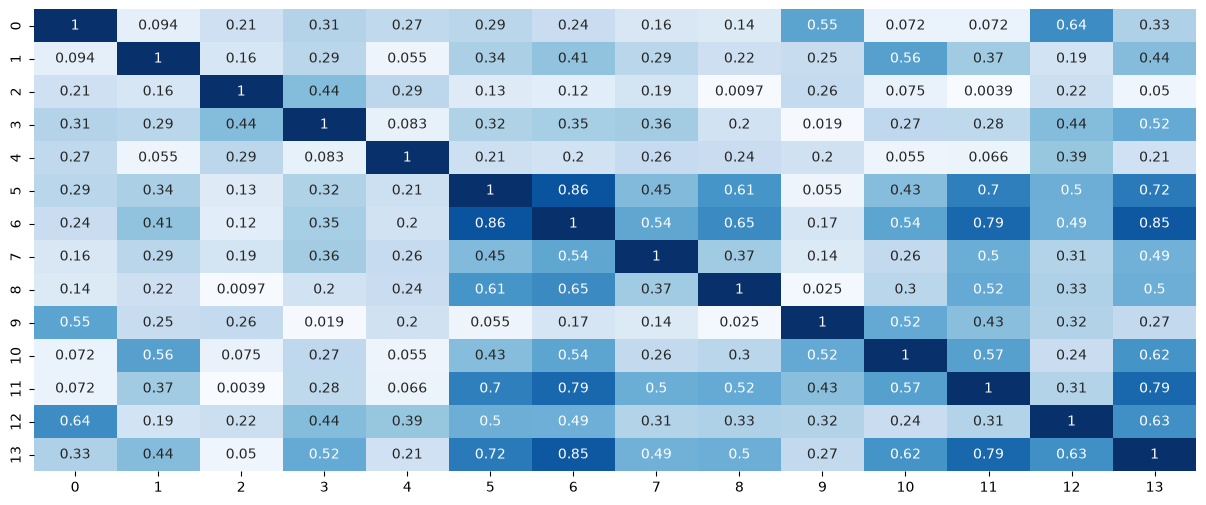

In [72]:
fig, ax= plt.subplots(figsize=(15,6))
sns.heatmap(data= data_df.corr().abs(),
            ax=ax,
            cmap='Blues'
            , annot=True,
            fmt='.2g',
            cbar=False
           )

In [73]:
labels= data_df[data_df.columns[-1]]
features_df=data_df.drop(data_df.columns[-1],axis=1)
labels.shape

(178,)

In [74]:
features_df.shape


(178, 13)

In [75]:
X_train,X_test,y_train,y_test=train_test_split(features_df,labels,
                                               test_size=TEST_SIZE,
                                               random_state=RANDOM_STATE,
                                               stratify=labels
                                              )
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(142, 13) (36, 13) (142,) (36,)


In [76]:
sc=StandardScaler()

X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

le=LabelEncoder()
y_train=le.fit_transform(y_train)
y_test=le.transform(y_test)

In [77]:
model= nn.Sequential(
    nn.Linear(13,8),
    nn.ReLU(),
    nn.Linear(8,3)
)

display(model)

model=model.to(device)

Sequential(
  (0): Linear(in_features=13, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=3, bias=True)
)

In [78]:
summary(model, (13,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                    [-1, 8]             112
              ReLU-2                    [-1, 8]               0
            Linear-3                    [-1, 3]              27
Total params: 139
Trainable params: 139
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


In [79]:
parameters = list(model.parameters())

print(f'Num Parameters {len(parameters)}')

print(f'Layer 1 Weights {parameters[0].shape}')

print(f'Layer 1 Bias {parameters[1].shape}')

print(f'Layer 2 Weights {parameters[2].shape}')

print(f'Layer 2 Bias {parameters[3].shape}')


Num Parameters 4
Layer 1 Weights torch.Size([8, 13])
Layer 1 Bias torch.Size([8])
Layer 2 Weights torch.Size([3, 8])
Layer 2 Bias torch.Size([3])


In [80]:
prediction = model(torch.tensor(X_train[:1], dtype=torch.float32, device=device))
prediction

tensor([[ 0.3531, -0.3311, -0.2378]], grad_fn=<AddmmBackward0>)

In [81]:
loss_fn= nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr=ALPHA )

In [82]:
train_x=torch.tensor(X_train, dtype=torch.float32,device=device)
train_y=torch.tensor(y_train, dtype=torch.int64,device=device)

test_x=torch.tensor(X_test, dtype=torch.float32,device=device)
test_y=torch.tensor(y_test, dtype=torch.int64,device=device)

In [83]:
pred = model(train_x[:1])
loss_fn(pred, train_y[:1])

tensor(1.4061, grad_fn=<NllLossBackward0>)

In [84]:
train_loss = []
test_loss = []

for epoch in range(EPOCHS):

    model.train() # set to training model

    outputs= model(train_x)  # Forward propogation

    loss=loss_fn(outputs, train_y) # Calculate Loss
    train_loss.append(loss.item())

    #Back Propagation
    optimizer.zero_grad() # reset

    loss.backward() #back Prop (dws dbs)

    optimizer.step() # W = W_alpha * dW

    with torch.inference_mode():
        model.eval()
        outputs = model(test_x) #Forward propagation
        tloss= loss_fn(outputs,test_y) # calculate loss
        test_loss.append(tloss.item())

    if epoch % 100 ==0:
        print(f'At epoch-{epoch:4d}: Loss - {loss.item():.4f}' f'Test Loss - {tloss.item():.4f}')

At epoch-   0: Loss - 1.1113Test Loss - 1.0688


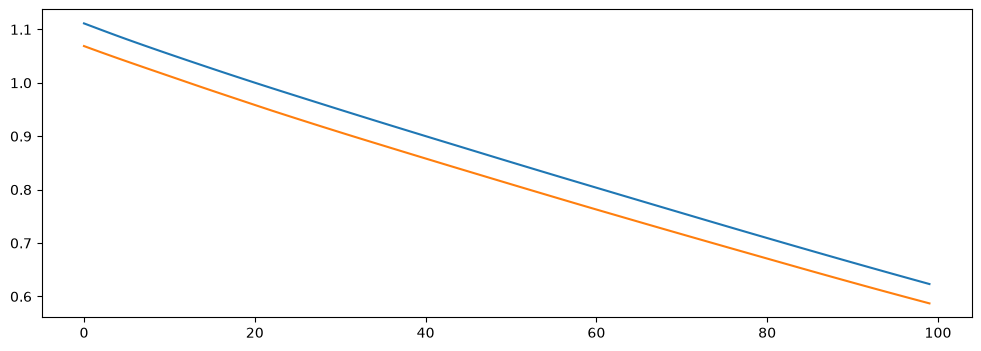

In [86]:
model.eval()

with torch.inference_mode():

    train_pred = model(train_x)

    test_pred = model(test_x)

type(train_pred), type(test_pred)

(torch.Tensor, torch.Tensor)

In [87]:
train_pred.argmax(dim=1)

tensor([0, 0, 1, 1, 2, 0, 0, 0, 0, 2, 2, 1, 0, 2, 0, 1, 0, 2, 0, 1, 0, 2, 1, 0,
        2, 0, 0, 1, 0, 0, 2, 0, 1, 2, 0, 1, 0, 2, 0, 1, 2, 2, 0, 0, 0, 1, 0, 2,
        0, 1, 1, 0, 1, 2, 2, 1, 2, 0, 0, 2, 2, 0, 2, 0, 1, 1, 2, 0, 0, 2, 0, 2,
        2, 2, 2, 0, 1, 1, 1, 0, 2, 0, 0, 1, 2, 2, 2, 2, 2, 2, 1, 0, 1, 2, 0, 2,
        0, 2, 1, 0, 2, 1, 1, 1, 1, 0, 2, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 2,
        0, 2, 1, 0, 1, 0, 2, 1, 0, 2, 2, 0, 2, 1, 2, 1, 0, 1, 0, 0, 2, 2])

In [88]:
y_train_pred = train_pred.argmax(dim=1).detach()  # remove computation Grrraph

y_train_pred = y_train_pred.cpu().numpy()

y_train_pred

array([0, 0, 1, 1, 2, 0, 0, 0, 0, 2, 2, 1, 0, 2, 0, 1, 0, 2, 0, 1, 0, 2,
       1, 0, 2, 0, 0, 1, 0, 0, 2, 0, 1, 2, 0, 1, 0, 2, 0, 1, 2, 2, 0, 0,
       0, 1, 0, 2, 0, 1, 1, 0, 1, 2, 2, 1, 2, 0, 0, 2, 2, 0, 2, 0, 1, 1,
       2, 0, 0, 2, 0, 2, 2, 2, 2, 0, 1, 1, 1, 0, 2, 0, 0, 1, 2, 2, 2, 2,
       2, 2, 1, 0, 1, 2, 0, 2, 0, 2, 1, 0, 2, 1, 1, 1, 1, 0, 2, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 2, 0, 2, 1, 0, 1, 0, 2, 1, 0, 2, 2, 0,
       2, 1, 2, 1, 0, 1, 0, 0, 2, 2])

In [89]:
from sklearn.metrics import f1_score
f_score=f1_score(y_train,y_train_pred,average='weighted')

accuracy_score(y_train, y_train_pred)
 

0.8450704225352113

<Axes: >

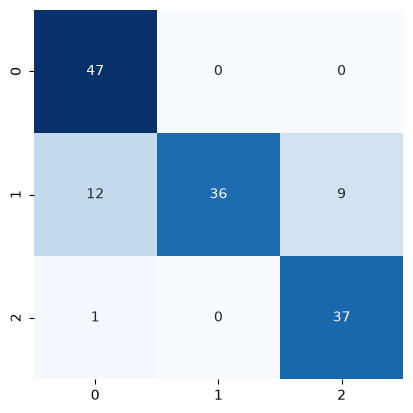

In [90]:
cm=confusion_matrix(y_train,y_train_pred)
sns.heatmap(cm,square=1,annot=True,cbar=0,cmap='Blues')